# K-Means: cuándo funciona y cuándo no

K-Means agrupa los puntos asignando cada uno al centroide más cercano. Eso implica tres supuestos: que conocemos el número de grupos, que los grupos son aproximadamente esféricos y que tienen tamaños y varianzas parecidos. En este notebook pongo a prueba esos supuestos con cuatro conjuntos de datos sintéticos.

> **Base:** el código parte del ejemplo [*Demonstration of k-means assumptions*](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html) de la documentación de scikit-learn (licencia BSD-3-Clause). La diferencia principal con el ejemplo es que en la segunda figura uso k = 5 en los cuatro conjuntos, lo que muestra qué pasa cuando el número de grupos es incorrecto en cada tipo de datos.

## 1. Datos

Se generan 1,500 puntos alrededor de tres centros con `make_blobs` y, a partir de ellos, tres variantes:

- **Anisotrópicos:** se aplica una transformación lineal que estira los grupos en diagonal.
- **Varianza desigual:** cada grupo tiene una dispersión distinta (1.0, 2.5 y 0.5).
- **Tamaños desiguales:** se conservan 500, 100 y 10 puntos de cada grupo.

In [1]:
import numpy as np

from sklearn.datasets import make_blobs

n_samples = 1500
random_state = 170
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]

X, y = make_blobs(n_samples=n_samples, random_state=random_state)
X_aniso = np.dot(X, transformation)  # Anisotropic blobs
X_varied, y_varied = make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)  # Unequal variance
X_filtered = np.vstack(
    (X[y == 0][:500], X[y == 1][:100], X[y == 2][:10])
)  # Unevenly sized blobs
y_filtered = [0] * 500 + [1] * 100 + [2] * 10

## 2. Grupos reales

Así se ven los cuatro conjuntos coloreados con la etiqueta verdadera de cada punto. Es la referencia para evaluar los resultados.

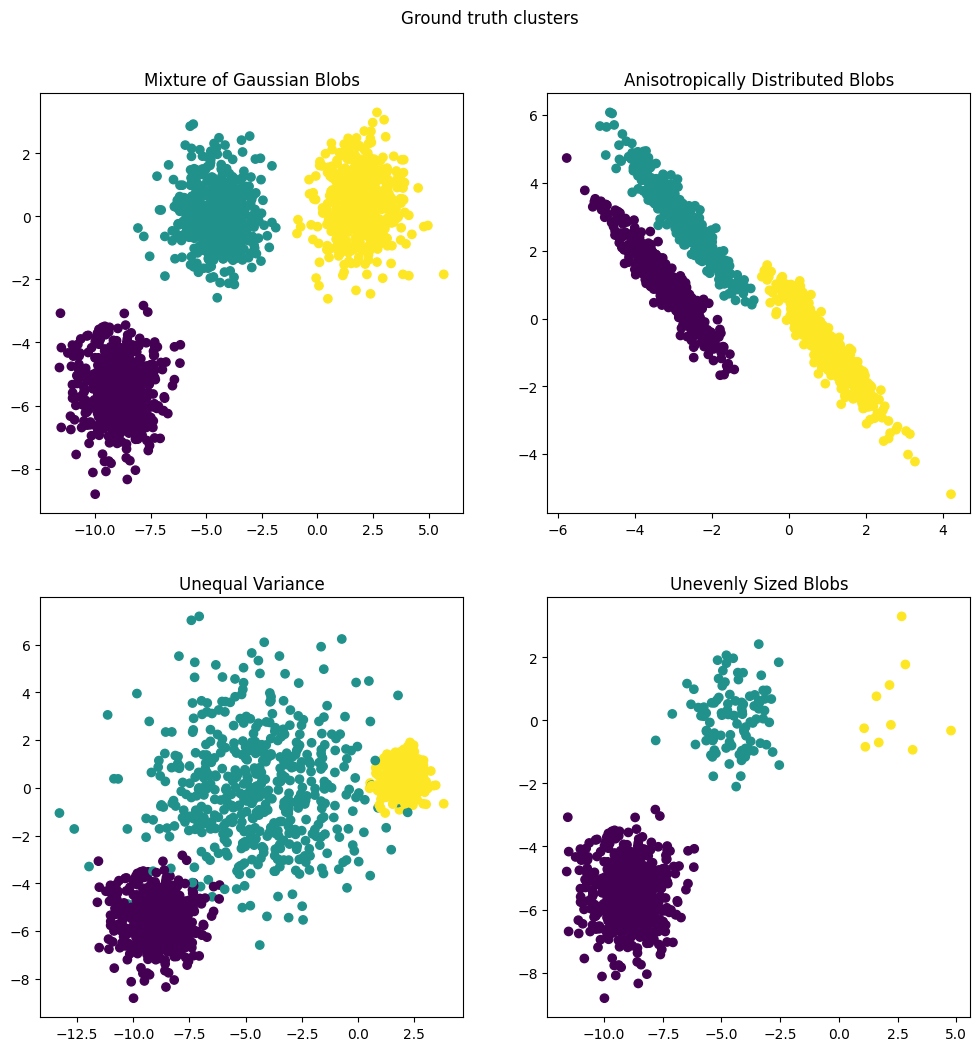

In [2]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))

axs[0, 0].scatter(X[:, 0], X[:, 1], c=y)
axs[0, 0].set_title("Mixture of Gaussian Blobs")

axs[0, 1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=y)
axs[0, 1].set_title("Anisotropically Distributed Blobs")

axs[1, 0].scatter(X_varied[:, 0], X_varied[:, 1], c=y_varied)
axs[1, 0].set_title("Unequal Variance")

axs[1, 1].scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_filtered)
axs[1, 1].set_title("Unevenly Sized Blobs")

plt.suptitle("Ground truth clusters").set_y(0.95)
plt.show()

## 3. K-Means con un número de grupos incorrecto (k = 5)

Los datos tienen 3 grupos, pero aquí K-Means busca 5. En todos los casos el algoritmo parte grupos reales en varios pedazos, porque siempre devuelve exactamente k grupos aunque los datos no los tengan. En los datos anisotrópicos además corta los grupos alargados de forma transversal: como mide distancias euclidianas al centroide, prefiere regiones redondas.

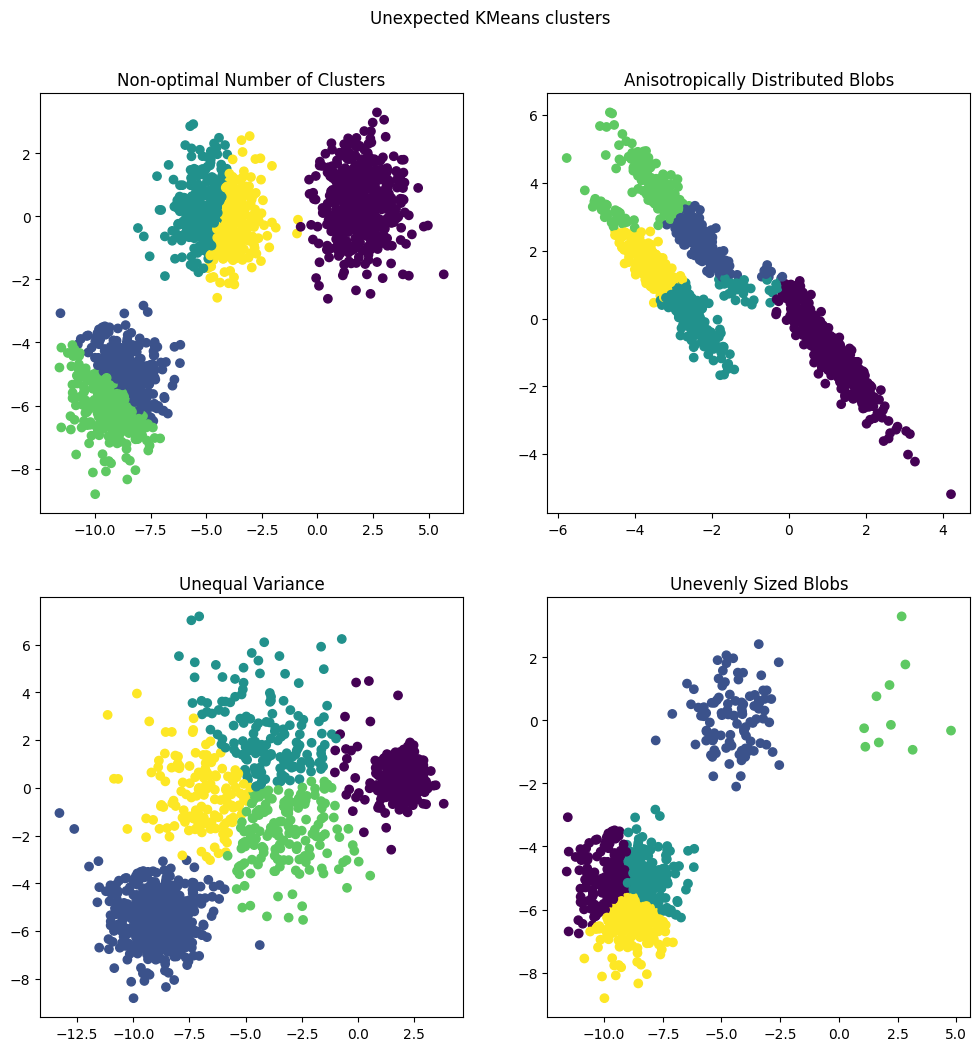

In [17]:
from sklearn.cluster import KMeans

common_params = {
    "n_init": "auto",
    "random_state": random_state,
}

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(12, 12))

y_pred = KMeans(n_clusters=5, **common_params).fit_predict(X)
axs[0, 0].scatter(X[:, 0], X[:, 1], c=y_pred)
axs[0, 0].set_title("Non-optimal Number of Clusters")

y_pred = KMeans(n_clusters=5, **common_params).fit_predict(X_aniso)
axs[0, 1].scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred)
axs[0, 1].set_title("Anisotropically Distributed Blobs")

y_pred = KMeans(n_clusters=5, **common_params).fit_predict(X_varied)
axs[1, 0].scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred)
axs[1, 0].set_title("Unequal Variance")

y_pred = KMeans(n_clusters=5, **common_params).fit_predict(X_filtered)
axs[1, 1].scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_pred)
axs[1, 1].set_title("Unevenly Sized Blobs")

plt.suptitle("Unexpected KMeans clusters").set_y(0.95)
plt.show()

## 4. Con el número correcto de grupos (k = 3)

Con k = 3 y grupos esféricos de tamaño similar, K-Means recupera los tres grupos reales: es el caso para el que el algoritmo está diseñado.

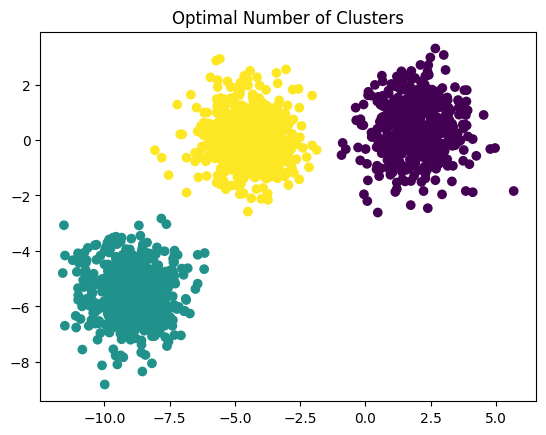

In [4]:
y_pred = KMeans(n_clusters=3, **common_params).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.title("Optimal Number of Clusters")
plt.show()

## 5. Tamaños desiguales con varias inicializaciones

K-Means depende de dónde coloca los centroides iniciales. Con `n_init=10` se ejecuta diez veces con inicios distintos y se queda con la mejor solución (la de menor inercia). Con k = 3 logra separar incluso el grupo de solo 10 puntos.

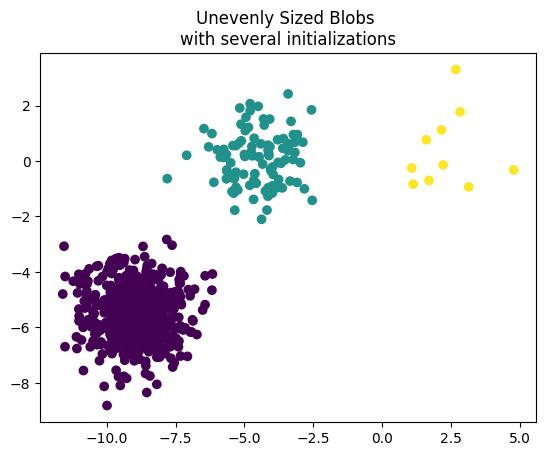

In [5]:
y_pred = KMeans(n_clusters=3, n_init=10, random_state=random_state).fit_predict(
    X_filtered
)
plt.scatter(X_filtered[:, 0], X_filtered[:, 1], c=y_pred)
plt.title("Unevenly Sized Blobs \nwith several initializations")
plt.show()

## 6. Alternativa: mezcla de gaussianas (GMM)

Un modelo de mezcla de gaussianas, ajustado con el algoritmo Expectation-Maximization, estima para cada grupo una media **y una matriz de covarianza**. Por eso puede representar grupos alargados o con dispersiones distintas, justo los dos casos en los que K-Means falla.

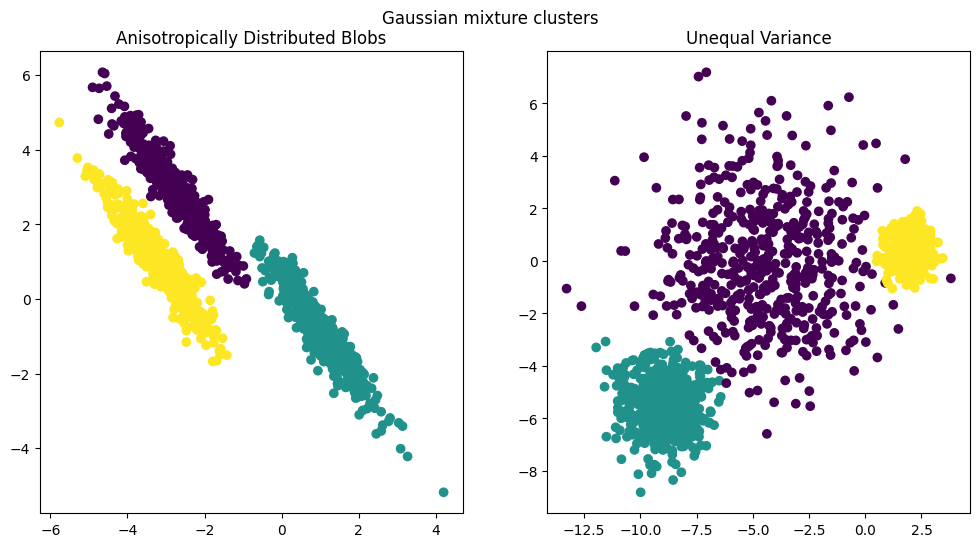

In [6]:
from sklearn.mixture import GaussianMixture

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

y_pred = GaussianMixture(n_components=3).fit_predict(X_aniso)
ax1.scatter(X_aniso[:, 0], X_aniso[:, 1], c=y_pred)
ax1.set_title("Anisotropically Distributed Blobs")

y_pred = GaussianMixture(n_components=3).fit_predict(X_varied)
ax2.scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred)
ax2.set_title("Unequal Variance")

plt.suptitle("Gaussian mixture clusters").set_y(0.95)
plt.show()

## Conclusiones

- K-Means es rápido y funciona bien cuando los grupos son compactos, de forma esférica y tamaño parecido, y cuando se conoce k.
- Si el número de grupos es incorrecto, K-Means no lo advierte: siempre devuelve k grupos.
- Con grupos alargados o de varianza muy distinta conviene un modelo que aprenda la forma de cada grupo, como GMM.
- Ejecutar varias inicializaciones (`n_init`) reduce el riesgo de quedarse en una mala solución.